<a href="https://colab.research.google.com/github/IanKNUIG/CT4105-Assignment-4/blob/main/CT4105_Assignment_4_Ian_Korpanty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ian Korpanty - ID 23383006 - 4BM1 - https://github.com/IanKNUIG/CT4105-Assignment-4.git

**Step 1 Prompt:**

(First I attached the .csv file) "Load the attached dataset into a pandas dataframe".

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/industrial_enclosures.csv')

# Display the first few rows and shape of the dataset
print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (640, 11)


,configuration_id,enclosure_height,side_panel_area,top_panel_area,envelope_area,compactness_index,orientation_code,clear_panel_fraction,panel_layout_code,heating_demand_index,cooling_demand_index
0,CFG-0001,3.5,245.0,220.5,686.0,0.74,3,0.10,S1,10.43,13.71
1,CFG-0002,7.0,343.0,147.0,637.0,0.79,4,0.25,S5,39.01,45.28
2,CFG-0003,7.0,416.5,122.5,661.5,0.76,4,0.25,S2,36.86,37.28
3,CFG-0004,7.0,343.0,147.0,637.0,0.79,2,0.40,S4,42.77,38.33
4,CFG-0005,7.0,318.5,147.0,612.5,0.82,2,0.25,S1,26.84,30.17


**Step 2:**

**Numerical measurements:** enclosure height, side panel area, top panel area, envelope area, compactness index, clear panel fraction, heating demand indec, cooling demand index,

**Categories or Identifiers:** configuration id, orientation code, panel code layout,

**Steps required to load it:**

From the code panel visible, the steps were:

1. import pandas as pd
2. load the dataset
3. display the first few rows of the dataset

**Step 3:**

Prompt:
"Using Python, identify:
1. Missing values
2. Suspicious values (seemingly unrealistic or highly inaccurate past reasonable variance)
3. Inconsistent cateogry labels in the dataset, including values that pandas may not automatically recognise as missing

mention where these values were located to enable manual verification by me"

In [ ]:
import pandas as pd
import numpy as np

# Ensure the dataframe is loaded
try:
    df
except NameError:
    df = pd.read_csv('/content/industrial_enclosures.csv')

# 1. Check for standard missing values (NaNs)
missing_counts = df.isnull().sum()
print("--- Standard Missing Values (NaN) count per column ---")
print(missing_counts[missing_counts > 0])
if missing_counts.sum() == 0:
    print("No standard NaN values found in the dataset.")

# 2. Check for inconsistent or hidden missing value placeholders in categorical / text columns
print("\n--- Categorical Unique Values (to identify hidden NaNs or inconsistencies) ---")
categorical_cols = ['orientation_code', 'panel_layout_code', 'clear_panel_fraction']
for col in categorical_cols:
    if col in df.columns:
        print(f"{col} unique values: {df[col].unique()}")

# Let's find any custom missing placeholders (like '?', 'N/A', 'none', '', 'nan' as string etc.)
placeholder_locations = {}
custom_placeholders = ['?', 'N/A', 'n/a', 'none', 'None', '', ' ', 'NULL', 'null', 'NaN', 'nan']
for col in df.columns:
    matches = df[df[col].astype(str).str.strip().isin(custom_placeholders)]
    if not matches.empty:
        placeholder_locations[col] = matches.index.tolist()

print("\n--- Non-standard Missing Value Placeholders ---")
if placeholder_locations:
    for col, idxs in placeholder_locations.items():
        print(f"Column '{col}' has potential placeholder strings at index positions: {idxs[:10]} (showing first 10, total {len(idxs)})")
else:
    print("No common string placeholders (like '?', 'N/A') were found in the dataset.")

# 3. Checking for suspicious numerical values (outliers or values outside reasonable variance/physical limits)
print("\n--- Numerical Column Summary Statistics ---")
display(df.describe())

# Check for specific potential logical/physical anomalies (e.g. negative areas, height <= 0, extremely high/low indexes)
suspicious_rows = {}

# Example logical checks:
# Areas should be positive
for col in ['side_panel_area', 'top_panel_area', 'envelope_area']:
    neg_or_zero = df[df[col] <= 0]
    if not neg_or_zero.empty:
        suspicious_rows[f"{col} <= 0"] = neg_or_zero.index.tolist()

# Enclosure height check (should be positive)
neg_height = df[df['enclosure_height'] <= 0]
if not neg_height.empty:
    suspicious_rows["enclosure_height <= 0"] = neg_height.index.tolist()

# Compactness index is usually between 0 and 1
out_of_bounds_compactness = df[(df['compactness_index'] < 0) | (df['compactness_index'] > 1)]
if not out_of_bounds_compactness.empty:
    suspicious_rows["compactness_index outside [0, 1]"] = out_of_bounds_compactness.index.tolist()

# Statistical outlier check (using Z-score > 4 or extreme values for heating/cooling demands)
for col in ['heating_demand_index', 'cooling_demand_index']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    # Extreme outliers: 3 * IQR
    outliers = df[(df[col] < (q1 - 3 * iqr)) | (df[col] > (q3 + 3 * iqr))]
    if not outliers.empty:
        suspicious_rows[f"{col} extreme statistical outliers"] = outliers.index.tolist()

print("\n--- Suspicious/Anomalous Value Locations ---")
if suspicious_rows:
    for key, idxs in suspicious_rows.items():
         print(f"{key} found at index positions: {idxs}")
else:
    print("No immediately obvious physical/logical anomalies found (such as negative areas or heights).")

DataFrame loaded successfully.

--- Standard Missing Values (NaN) count per column ---
envelope_area           2
heating_demand_index    2
cooling_demand_index    4
dtype: int64

--- Categorical Unique Values (to identify hidden NaNs or inconsistencies) ---
orientation_code unique values: [3 4 2 5]
panel_layout_code unique values: ['S1' 'S5' 'S2' 'S4' 'S3' 'S0' 'S2 ' 's3' 'S3 ' 'S4 ' 's2']
clear_panel_fraction unique values: [0.1  0.25 0.4  0.  ]

--- Non-standard Missing Value Placeholders ---
Column 'envelope_area' has potential placeholder strings at index positions: [15, 280] (showing first 10, total 2)
Column 'heating_demand_index' has potential placeholder strings at index positions: [383, 526] (showing first 10, total 2)
Column 'cooling_demand_index' has potential placeholder strings at index positions: [434, 479, 485, 543] (showing first 10, total 4)

--- Numerical Column Summary Statistics ---


,enclosure_height,side_panel_area,top_panel_area,envelope_area,compactness_index,orientation_code,clear_panel_fraction,heating_demand_index,cooling_demand_index
count,640.000000,640.000000,640.000000,638.000000,640.000000,640.000000,640.000000,638.000000,636.000000
mean,5.233594,318.729688,176.782813,664.290752,0.763641,3.514063,0.233594,17.393150,24.457186
std,1.751292,44.095567,45.400234,144.616188,0.106346,1.107573,0.134663,70.640041,9.442426
min,3.500000,245.000000,110.250000,-999.000000,0.620000,2.000000,0.000000,-999.000000,10.900000
25%,3.500000,294.000000,122.500000,594.125000,0.690000,3.000000,0.100000,12.950000,15.552500
50%,3.500000,318.500000,220.500000,686.000000,0.740000,4.000000,0.250000,18.480000,21.950000
75%,7.000000,343.000000,220.500000,735.000000,0.820000,4.000000,0.400000,31.772500,32.972500
max,7.000000,416.500000,220.500000,808.500000,0.980000,5.000000,0.400000,42.960000,48.030000



--- Suspicious/Anomalous Value Locations ---
envelope_area <= 0 found at index positions: [134, 450, 453]
heating_demand_index extreme statistical outliers found at index positions: [5, 167, 523]


The first prompt failed due to runtime for the session ended, and I prompted "Please explain this error:

NameError: name 'dF' is not defined"

I then reran the correct code once Gemini recognised its mistake.

It then failed to read the .csv file after I had attached it earlier in the work session. I reattached the file and prompted it to "Execute this original prompt now that the .csv file is attached: Using Python, identify:
1. Missing values
2. Suspicious values (seemingly unrealistic or highly inaccurate past reasonable variance)
3. Inconsistent cateogry labels in the dataset, including values that pandas may not automatically recognise as missing

mention where these values were located to enable manual verification by me"



**Step 3: Reporting Findings (Adapted from Gemini output):**

**Standard Missing Values (NaN) count per column:**
envelope_area           2
heating_demand_index    2
cooling_demand_index    4
dtype: int64



**Categorical Unique Values (to identify hidden NaNs or inconsistencies)**
orientation_code unique values: [3 4 2 5]
panel_layout_code unique values: ['S1' 'S5' 'S2' 'S4' 'S3' 'S0' 'S2 ' 's3' 'S3 ' 'S4 ' 's2']
clear_panel_fraction unique values: [0.1  0.25 0.4  0.  ]

**Non-standard Missing Value Placeholders**
Column 'envelope_area' has potential
placeholder strings at index positions: [15, 280] (showing first 10, total 2)

**Column 'heating_demand_index' has potential placeholder strings at index positions:** [383, 526] (showing first 10, total 2)
Column 'cooling_demand_index' has potential placeholder strings at index positions: [434, 479, 485, 543] (showing first 10, total 4)



**Step 4: Cleaning the data**

I reviewed the data dictionary to understand what the expected units/expected values should be. Once I did that and after having examined the identified errors in the previous step, I prompted it the following:

"Clean the dataset for data analysis and plotting of graphs/charts, including but not limited to the following:

- Remove any rows which feature placeholder values

- Fix any inconsistent labelling of the same intended value "e.g s2, S2""

I identified some values were inconsistenly labelled, and after having manually inspected the dataset in Excel, I decided to remove the rows with placeholder values as there were 640 rows of data and not many rows were reported to have placeholder values in step 3.

**Step 5:**
Prompt: "Using the cleaned dataset, calculate the following:

1. Minimum for numerical variables
2. Maximum for numerical variables
3. Mean for numerical variables
4. Standard deviation for numerical variables
5. Frequency counts for categorical variables"

**Step 6:**

After examining the variables and overall dataset in Excel, I came up with the following variables comparisons and graph for step 6:

Prompt:

"Create three plots, labelled, laid out and examining the following:

1. A histogram of Enclosure Height, titled "Enclosure Height"

2. A scatter plot of Compactness Index against Heating Demand, titled "Compactness Index vs. Heating Demand"

3. A plot comparing the numerical variable of area, between the side panel and the top panel, titled "Side Panel vs. Top Panel Area""


After seeing the output was not ideal for analysis, I instead prompted Gemini to assess which variable plots for the requested types of graphs would highlight the most significant/important relationships to assess/examine:

Prompt #2 (Step 6):

"Create three plots, examining the most significant relationships you identify in the dataset for visual data analysis and interpretation:

1. A histogram of a numerical variable

2. A scatter plot comparing two numerical variables

3. A plot comparing a numerical variable across categories"

**Step 7:** (Graphs analysed from the AI-generated, second attempt)

1. **Observation:** The histogram of heating demand index shows a bimodal distribution, with the peaks of both occuring at approximately ~13 and ~31.

**Engineering Interpretation:** When observing the heating demand index measures, this bimodal distribution may indicate customer preference for certain "classes" of industrial equipment enclosure, as the peaks are relatively well-pronounced and the edges as well as the central values are noticeably lower in frequency than the two peak values. This may indicate that certain enclosures house a specific range of equipment, such as for domestic or office space applications (i.e. widely used, standardised equipment).

2. **Observation:** The Graph comparing compactness index against heating index, with a coloured legend showing the enclosure height shows a clear relationship between the enclosure height and the cooling demand index. It shows that the larger enclosure height occupies the higher two thirds (or the upper ~66%) of the total cooling demand index range.

**Engineering Interpretation:** It can be inferred that it could relate to the power the system may have to draw in order to cool itself during operation. While it is not reasonable to automatically assume that the larger enclosure height itself causes higher cooling demand index values, it could be suggested that a more powerful heat-generating unit, or machine is placed in the taller industrial enclosure and thus the cooling demand is increased. In short, it is important to not automatically assess correlation with causation and in this case it might be due to the machinery housed inside the enclosure increasing the cooling demand during operation to either maintain saefty, functionality, energy efficiency, or all three.

**Step 8:**

I checked the two graphs I examined in step 7, the histogram and the scatter plot.

I reproduced them using the original dataset in Excel, adjusting axis settings and formatting to replicate the graphs for comparison to the AI-generated ones. I then visually inspected the graphs to ensure the main trends and expected data ranges were consistent across the AI-generated and manually produced graphs.

Below are the results of the reproduced graphs. It must be noted that they reproduce the graphs Gemini produced to a high level of accuracy, however small inaccuracies remain which could be attributed to the 8 rows of data being eliminated during the data cleaning process.

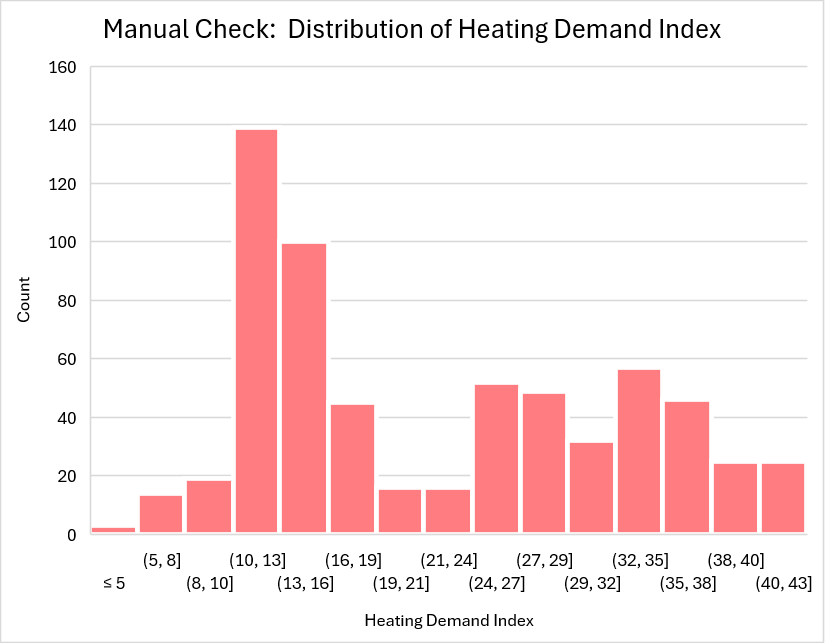

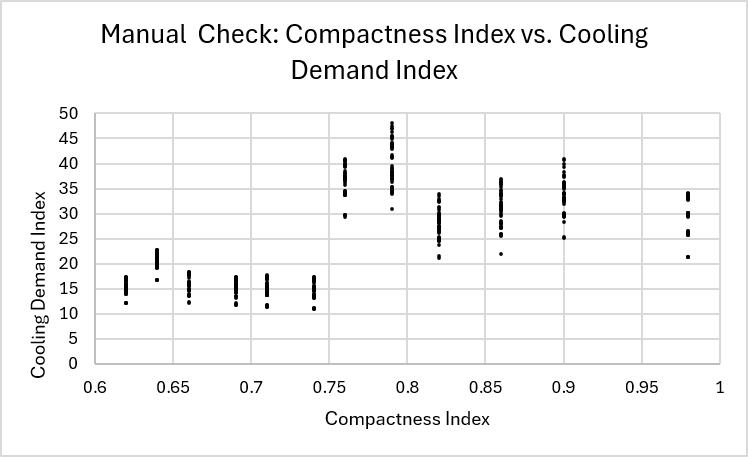

**Step 9:**

**Summary of main findings:**

Errors in data may be subtle and not easily noticeable, such as the case in step 4 where several errors were not caught during an initial scan I did beforehand of the data, however upon more thorough examining placeholder values and inconsistent labels became apparent in the data.

Overall, the dataset was largely usable for proper data analysis once cleaned, as Gemini had only removed 8 rows of an original 640 (1.25% of original dataset) for data cleaning.

**Further Investigation Necessary:**

It must be further investigated how the charts shown in step 8 are produced when graphing the cleaned dataset, to fully ensure that the AI had not made any mistakes in analysing and graphing the data. It is expected that 1.25% removal of the data from the original dataset would not harm the comparison accuracy too significantly, it is the appropraite method to fully provide complete validation over the AI-generated outputs.

**Errors or Incorrect Assumptions Encountered in AI coding Assistance:**

The only errors encountered were from timeout-related errors as mentioned in earlier steps, overall Gemini performed very well to clean the data, produce the plots worthy of discussion and analysis, as well as identify aspects of the original dataset to clean for plotting.